In [23]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

# Regularization in Regression

Regularization - modelin öyrənməsi zamanı overfiting-in qarşısını, modelin böyük koffisientlərinə görə "cərimələr" tətbiq edərək alır.

### Lasso Regression(L1 Regularization) - **L**east **A**bsolute **S**hrinkage and **S**election **O**perator
Cərimə: əmsalların mütləq qiymətlərinin cəmi

$$
L_{Lasso} = min(\sum(y-\hat{y})^2 +\lambda\sum|w_j|
$$

$$
L_{Lasso} = MSE + \lambda\sum_{j=1}^n|w_j|
$$

Təsiri:
- Bəzi əmsalları tam sıfıra endirə bilər
- Əlamətlərin avtomatik seçilməsini (Feature Selection) həyata keçirə bilər

### Ridge Regression(L2 Regularization)
Cərimə: əmsalların kvadratları cəmi

$$
L_{Ridge} = min(\sum(y-\hat{y})^2 +\lambda\sum {w_j^2}
$$

$$
L_{Ridge} = MSE + \lambda\sum_{j=1}^nw_j^2
$$

Təsiri:
- Bəzi əmsalların qiymətlərini kiçildir
- Əlamətlərin adətən tam sıfıra endirmir, yəni əlamətləri modeldən çıxarmır
- Modelin daha stabil olmasını təyin eləyir
### ElasticNet Regression(L1 + L2)


#### Hansı üsuldan nə zaman istifadə etməli:
| Method            | Nə zaman istifadə olunur                                                          |
|-------------------|-----------------------------------------------------------------------------------|
| Lasso(L1)         | Ən vacib əlamətləri seçmək və lazımsız əlamətləri modeldən çıxarmaq lazım olduqda |
| Ridge(L2)         | Əlamətlərin sayı çox olduqda və onların hamsını modeldə saxlamaq istəyəndə        |
| ElasticNet(L1+L2) | Əlamətlər arasında güclü korrelyasiya olduqda                                     |


In [24]:
np.random.seed(42)
n = 120

X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

y = 0.5*X[:,0]**3 - 3*X[:,0]**2 + 2*X[:,0] + noise

In [25]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [26]:
def train_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"""=== {name} ===
    R2 score:   {r2_score(y_test, y_pred):.3f},
    RMSE:       {root_mean_squared_error(y_test, y_pred):.3f}
""")
    return model

In [27]:
degree = 10

ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0)),
])

lasso = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.05, max_iter=20000)),
])

elastic_net = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('elastic_net', ElasticNet(alpha=0.05, max_iter=20000, l1_ratio=0.3)),
])

ridge = train_model(ridge, 'Ridge')
lasso = train_model(lasso, 'Lasso')
elastic_net = train_model(elastic_net, 'ElasticNet')


=== Ridge ===
    R2 score:   0.947,
    RMSE:       5.613

=== Lasso ===
    R2 score:   0.953,
    RMSE:       5.311

=== ElasticNet ===
    R2 score:   0.929,
    RMSE:       6.511



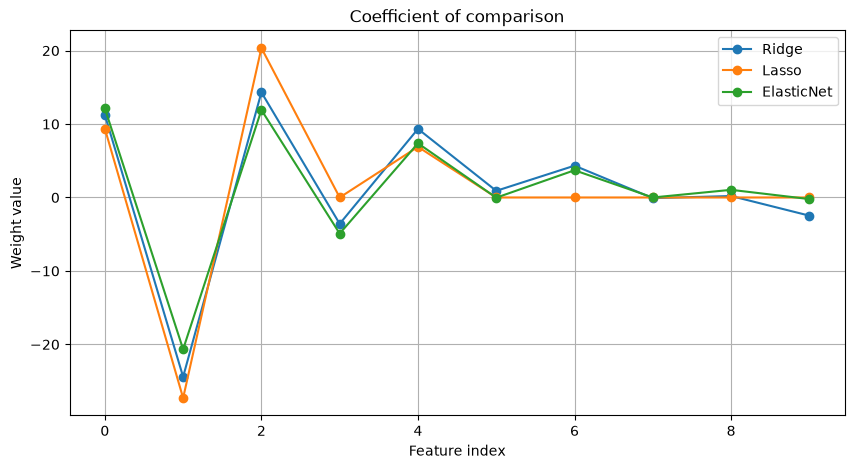

In [28]:
models = {
    "Ridge": ridge.named_steps["ridge"].coef_,
    "Lasso": lasso.named_steps["lasso"].coef_,
    "ElasticNet": elastic_net.named_steps["elastic_net"].coef_,
}

plt.figure(figsize=(10, 5))
for name, coef in models.items():
    plt.plot(coef, marker='o', label=name)

plt.title("Coefficient of comparison")
plt.xlabel("Feature index")
plt.ylabel("Weight value")
plt.legend()
plt.grid(True)
plt.show()